In [ ]:
# ==========================================
# CELL 1: Mount Google Drive & Setup Device
# ==========================================
import os
import torch
from google.colab import drive

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Setup Device (GPU if available)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"🚀 Using compute device: {device}")

# 3. Locate the trained weights file
possible_weight_paths = [
    '/content/drive/MyDrive/Capstone_Kidney_Project/best_pcsa_kidneynext_60epochs_AUGMENTED.pth',
    '/content/drive/MyDrive/best_pcsa_kidneynext_60epochs_AUGMENTED.pth',
    'best_pcsa_kidneynext_60epochs_AUGMENTED.pth',
    'best_pcsa_kidneynext_AUGMENTED.pth'
]

weights_path = None
for path in possible_weight_paths:
    if os.path.exists(path):
        weights_path = path
        break

if weights_path:
    print(f"✅ Found model weights at: {weights_path}")
else:
    raise FileNotFoundError("❌ Could not find 'best_pcsa_kidneynext_60epochs_AUGMENTED.pth'. Please check your Google Drive folder.")


Mounted at /content/drive
🚀 Using compute device: cpu
✅ Found model weights at: /content/drive/MyDrive/Capstone_Kidney_Project/best_pcsa_kidneynext_60epochs_AUGMENTED.pth


In [ ]:
# ==============================================================
# CELL 2 (FIXED): Auto-Dataset Download & Test Pipeline Setup
# ==============================================================
import os
import glob
import shutil
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split

# -------------------------------------------------------------
# 1. Check if dataset exists; if not, automatically retrieve it
# -------------------------------------------------------------
if not os.path.exists('kidney_dataset/kidneyData.csv'):
    print("⚠️ 'kidney_dataset/kidneyData.csv' not found in current Colab session.")

    # Check if a zip archive exists in Colab or Google Drive
    drive_zips = (
        glob.glob('/content/*ct-kidney*.zip') +
        glob.glob('/content/drive/MyDrive/**/*ct-kidney*.zip', recursive=True) +
        glob.glob('/content/drive/MyDrive/**/Capstone_Kidney_Project/*.zip', recursive=True)
    )

    if drive_zips:
        zip_path = drive_zips[0]
        print(f"📦 Found saved archive at: {zip_path}")
        print("📂 Extracting to kidney_dataset/ ...")
        os.system(f"unzip -q '{zip_path}' -d kidney_dataset/")
    else:
        # Download automatically via kagglehub (public dataset, no kaggle.json required!)
        print("📥 Downloading dataset automatically via kagglehub (takes ~30-40 seconds)...")
        !pip install -q kagglehub
        import kagglehub
        downloaded_dir = kagglehub.dataset_download("nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone")
        print(f"✅ Downloaded to: {downloaded_dir}")

        os.makedirs("kidney_dataset", exist_ok=True)
        os.system(f"cp -rf '{downloaded_dir}'/* kidney_dataset/")

# Locate the CSV
csv_path = 'kidney_dataset/kidneyData.csv'
if not os.path.exists(csv_path):
    found_csvs = glob.glob('**/kidneyData.csv', recursive=True)
    if found_csvs:
        csv_path = found_csvs[0]

print(f"📄 Using CSV: {csv_path}")

# -------------------------------------------------------------
# 2. Load CSV and map real image paths
# -------------------------------------------------------------
df = pd.read_csv(csv_path)

all_image_paths = glob.glob('kidney_dataset/**/*.jpg', recursive=True)
if not all_image_paths:
    all_image_paths = glob.glob('**/*.jpg', recursive=True)

path_dict = {os.path.basename(p): p for p in all_image_paths}
df['path'] = df['path'].apply(lambda x: path_dict.get(os.path.basename(x)))
df = df.dropna(subset=['path'])

print(f"✅ Total images mapped: {len(df)} (Expected: 12446)")

# -------------------------------------------------------------
# 3. Exact Reproducible Test Split (Stratified, random_state=42)
# -------------------------------------------------------------
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['Class'], random_state=42)
train_df, val_df = train_test_split(train_df, test_size=0.3, stratify=train_df['Class'], random_state=42)

test_df = test_df.reset_index(drop=True)
print(f"✅ Test dataset size: {len(test_df)} images (Expected: 2490)")

# -------------------------------------------------------------
# 4. Transformations & Dataset with File Path Tracking
# -------------------------------------------------------------
test_val_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class CTKidneyTestDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):
        img_path = self.dataframe.iloc[idx]['path']
        image = Image.open(img_path).convert('RGB')
        label = int(self.dataframe.iloc[idx]['target'])
        if self.transform:
            image = self.transform(image)
        return image, torch.tensor(label, dtype=torch.long), img_path

test_dataset = CTKidneyTestDataset(test_df, transform=test_val_transforms)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)
class_names = ['Cyst', 'Normal', 'Stone', 'Tumor']

print("🚀 Data pipeline successfully ready for evaluation!")


⚠️ 'kidney_dataset/kidneyData.csv' not found in current Colab session.
📥 Downloading dataset automatically via kagglehub (takes ~30-40 seconds)...
Using Colab cache for faster access to the 'ct-kidney-dataset-normal-cyst-tumor-and-stone' dataset.
✅ Downloaded to: /kaggle/input/ct-kidney-dataset-normal-cyst-tumor-and-stone
📄 Using CSV: kidney_dataset/kidneyData.csv
✅ Total images mapped: 12446 (Expected: 12446)
✅ Test dataset size: 2490 images (Expected: 2490)
🚀 Data pipeline successfully ready for evaluation!


In [ ]:
# ==============================================================
# CELL 3: PCSA-KidneyNeXt Architecture Definition
# ==============================================================
import torch
import torch.nn as nn
import torch.nn.functional as F

# 1. The PCSA (Pyramid Channel and Spatial Attention) Module
class PCSAModule(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super(PCSAModule, self).__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)

        self.fc = nn.Sequential(
            nn.Linear(in_channels, in_channels // reduction, bias=False),
            nn.ReLU(inplace=True),
            nn.Linear(in_channels // reduction, in_channels, bias=False)
        )

        self.conv_spatial_3 = nn.Conv2d(2, 1, kernel_size=3, padding=1, bias=False)
        self.conv_spatial_5 = nn.Conv2d(2, 1, kernel_size=5, padding=2, bias=False)

    def forward(self, x):
        b, c, _, _ = x.size()
        y_avg = self.fc(self.avg_pool(x).view(b, c)).view(b, c, 1, 1)
        y_max = self.fc(self.max_pool(x).view(b, c)).view(b, c, 1, 1)
        channel_weights = torch.sigmoid(y_avg + y_max)
        x_out = x * channel_weights

        max_out, _ = torch.max(x_out, dim=1, keepdim=True)
        avg_out = torch.mean(x_out, dim=1, keepdim=True)
        spatial_in = torch.cat([max_out, avg_out], dim=1)

        spatial_weights_3 = self.conv_spatial_3(spatial_in)
        spatial_weights_5 = self.conv_spatial_5(spatial_in)
        spatial_weights = torch.sigmoid(spatial_weights_3 + spatial_weights_5)

        return x_out * spatial_weights

# 2. The Custom KidneyNeXt Block
class PCSA_KidneyNeXt_Block(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super(PCSA_KidneyNeXt_Block, self).__init__()
        self.max_pool = nn.MaxPool2d(kernel_size=3, stride=stride, padding=1)
        self.avg_pool = nn.AvgPool2d(kernel_size=3, stride=stride, padding=1)

        self.g_conv1 = nn.Conv2d(in_channels, in_channels, kernel_size=3, stride=stride, padding=1, groups=in_channels, bias=False)
        self.g_conv2 = nn.Conv2d(in_channels, in_channels, kernel_size=5, stride=stride, padding=2, groups=in_channels, bias=False)

        concat_channels = in_channels * 4
        self.compress_conv = nn.Conv2d(concat_channels, out_channels, kernel_size=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)
        self.gelu = nn.GELU()
        self.pcsa = PCSAModule(out_channels)

        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x):
        out = torch.cat([self.max_pool(x), self.avg_pool(x), self.g_conv1(x), self.g_conv2(x)], dim=1)
        out = self.compress_conv(out)
        out = self.bn(out)
        out = self.gelu(out)
        out = self.pcsa(out)
        out = out + self.shortcut(x)
        return out

# 3. The Complete PCSA-KidneyNeXt Model
class PCSA_KidneyNeXt(nn.Module):
    def __init__(self, num_classes=4):
        super(PCSA_KidneyNeXt, self).__init__()
        self.stem_conv1 = nn.Conv2d(3, 96, kernel_size=4, stride=4, padding=0, bias=False)
        self.stem_conv2 = nn.Conv2d(3, 96, kernel_size=4, stride=4, padding=0, bias=False)
        self.stem_bn = nn.BatchNorm2d(96)
        self.stem_gelu = nn.GELU()

        self.stage1 = PCSA_KidneyNeXt_Block(in_channels=96, out_channels=96, stride=1)
        self.stage2 = PCSA_KidneyNeXt_Block(in_channels=96, out_channels=192, stride=2)
        self.stage3 = PCSA_KidneyNeXt_Block(in_channels=192, out_channels=384, stride=2)
        self.stage4 = PCSA_KidneyNeXt_Block(in_channels=384, out_channels=768, stride=2)

        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(768, num_classes)

    def forward(self, x):
        out = (self.stem_conv1(x) + self.stem_conv2(x)) / 2.0
        out = self.stem_gelu(self.stem_bn(out))
        out = self.stage1(out)
        out = self.stage2(out)
        out = self.stage3(out)
        out = self.stage4(out)
        out = self.global_pool(out)
        out = torch.flatten(out, 1)
        out = self.classifier(out)
        return out

print("✅ Model architecture compiled successfully!")


✅ Model architecture compiled successfully!


In [ ]:
# ==============================================================
# CELL 4: Initialize Model & Load Weights
# ==============================================================
model = PCSA_KidneyNeXt(num_classes=4).to(device)

state_dict = torch.load(weights_path, map_location=device)
model.load_state_dict(state_dict)
model.eval()

print("🧠 PCSA-KidneyNeXt successfully initialized and weights loaded in eval mode!")


🧠 PCSA-KidneyNeXt successfully initialized and weights loaded in eval mode!


In [ ]:
# ==============================================================
# CELL 5: Test Evaluation & Misclassification Mining
# ==============================================================
import numpy as np
import pandas as pd

misclassified_records = []
total_test_samples = 0
correct_samples = 0

print("🔍 Evaluating test set and mining misclassifications...")

with torch.no_grad():
    for inputs, labels, paths in test_loader:
        inputs = inputs.to(device)
        labels = labels.to(device)

        outputs = model(inputs)
        probs = F.softmax(outputs, dim=1)
        confs, preds = torch.max(probs, 1)

        total_test_samples += labels.size(0)
        correct_samples += torch.sum(preds == labels).item()

        # Check for misclassifications in current batch
        mismatch_mask = (preds != labels)
        if torch.any(mismatch_mask):
            mismatch_indices = torch.where(mismatch_mask)[0].cpu().numpy()
            for idx in mismatch_indices:
                p_path = paths[idx]
                true_lbl = labels[idx].item()
                pred_lbl = preds[idx].item()
                conf_val = confs[idx].item()
                prob_dist = probs[idx].cpu().numpy()

                misclassified_records.append({
                    'filename': os.path.basename(p_path),
                    'full_path': p_path,
                    'actual_class': class_names[true_lbl],
                    'predicted_class': class_names[pred_lbl],
                    'confidence': f"{conf_val * 100:.2f}%",
                    'prob_Cyst': f"{prob_dist[0] * 100:.2f}%",
                    'prob_Normal': f"{prob_dist[1] * 100:.2f}%",
                    'prob_Stone': f"{prob_dist[2] * 100:.2f}%",
                    'prob_Tumor': f"{prob_dist[3] * 100:.2f}%"
                })

misclassified_df = pd.DataFrame(misclassified_records)
accuracy = (correct_samples / total_test_samples) * 100

print(f"\n🎯 Total Test Samples: {total_test_samples}")
print(f"✅ Accuracy: {accuracy:.4f}% ({correct_samples}/{total_test_samples})")
print(f"⚠️ Total Misclassified Images Found: {len(misclassified_df)}")

# Display the misclassified images dataframe
display(misclassified_df)


🔍 Evaluating test set and mining misclassifications...

🎯 Total Test Samples: 2490
✅ Accuracy: 99.9197% (2488/2490)
⚠️ Total Misclassified Images Found: 2


,filename,full_path,actual_class,predicted_class,confidence,prob_Cyst,prob_Normal,prob_Stone,prob_Tumor
0,Cyst- (3165).jpg,kidney_dataset/CT-KIDNEY-DATASET-Normal-Cyst-T...,Cyst,Stone,61.37%,38.63%,0.00%,61.37%,0.00%
1,Cyst- (1576).jpg,kidney_dataset/CT-KIDNEY-DATASET-Normal-Cyst-T...,Cyst,Stone,65.96%,34.04%,0.00%,65.96%,0.00%


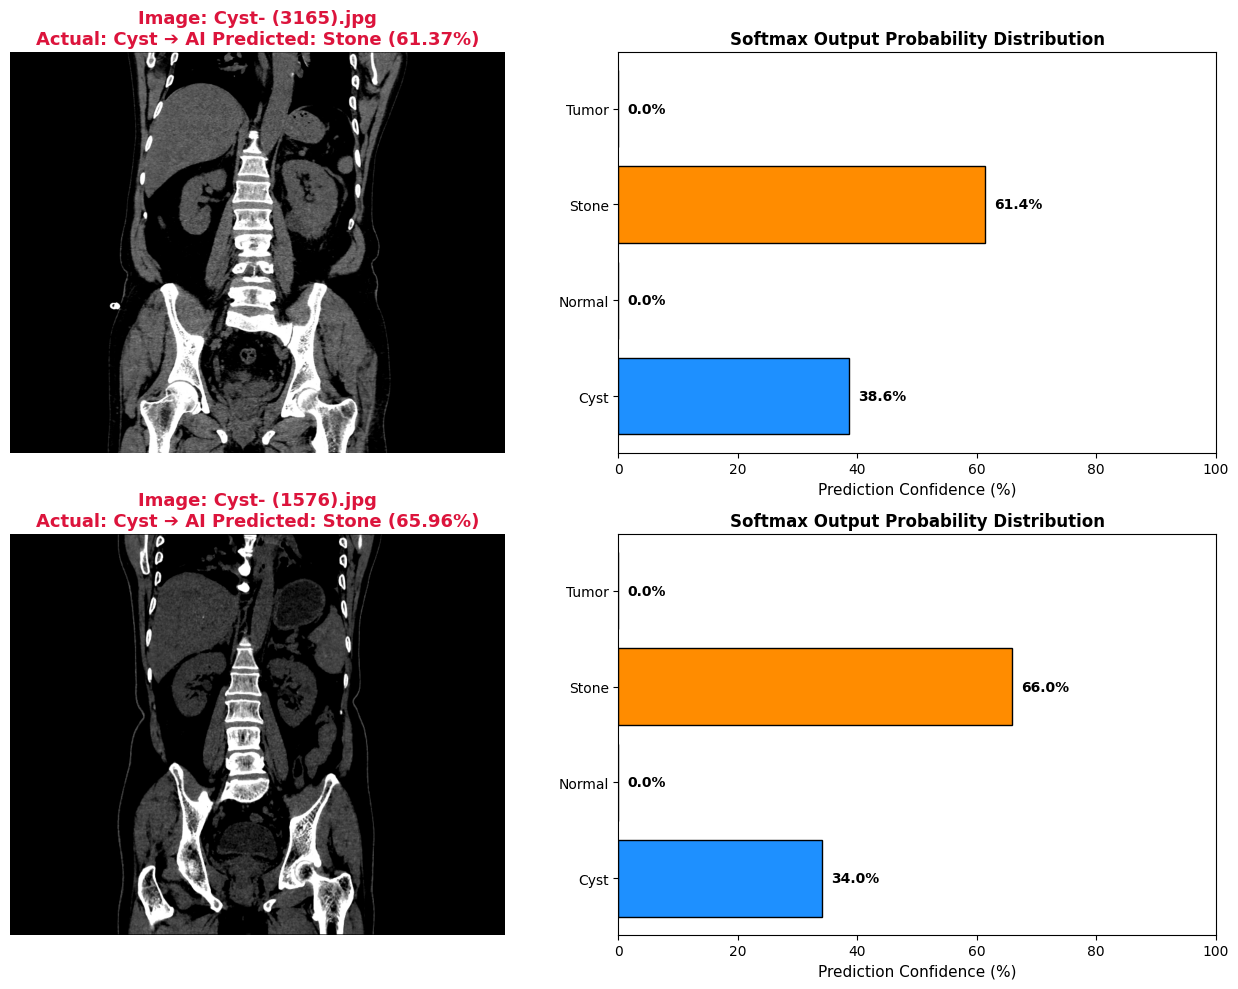

In [ ]:
# ==============================================================
# CELL 6: Visualize Misclassified Images & Probability Graphs
# ==============================================================
import matplotlib.pyplot as plt

num_errors = len(misclassified_df)

if num_errors == 0:
    print("🎉 No misclassifications found!")
else:
    fig, axes = plt.subplots(num_errors, 2, figsize=(13, 5 * num_errors))
    if num_errors == 1:
        axes = np.expand_dims(axes, 0)

    for i, row in misclassified_df.iterrows():
        # 1. Display CT Scan
        img = Image.open(row['full_path']).convert('RGB')
        axes[i, 0].imshow(img)
        axes[i, 0].axis('off')
        axes[i, 0].set_title(
            f"Image: {row['filename']}\nActual: {row['actual_class']} ➔ AI Predicted: {row['predicted_class']} ({row['confidence']})",
            fontsize=13, fontweight='bold', color='crimson'
        )

        # 2. Display Class Probabilities Bar Chart
        probs = [
            float(row['prob_Cyst'].replace('%', '')),
            float(row['prob_Normal'].replace('%', '')),
            float(row['prob_Stone'].replace('%', '')),
            float(row['prob_Tumor'].replace('%', ''))
        ]
        bar_colors = ['dodgerblue', 'forestgreen', 'darkorange', 'purple']
        bars = axes[i, 1].barh(class_names, probs, color=bar_colors, edgecolor='black')
        axes[i, 1].set_xlim(0, 100)
        axes[i, 1].set_xlabel('Prediction Confidence (%)', fontsize=11)
        axes[i, 1].set_title('Softmax Output Probability Distribution', fontsize=12, fontweight='bold')

        # Add text labels on the bars
        for bar, p in zip(bars, probs):
            axes[i, 1].text(bar.get_width() + 1.5, bar.get_y() + bar.get_height()/2, f"{p:.1f}%", va='center', fontsize=10, fontweight='bold')

    plt.tight_layout()
    plt.show()


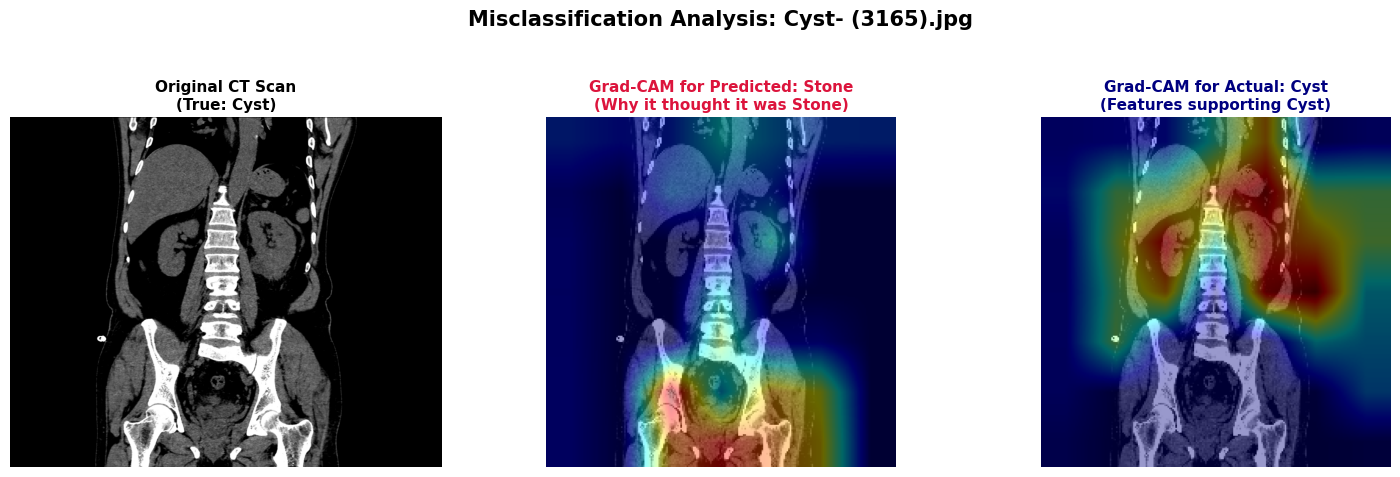

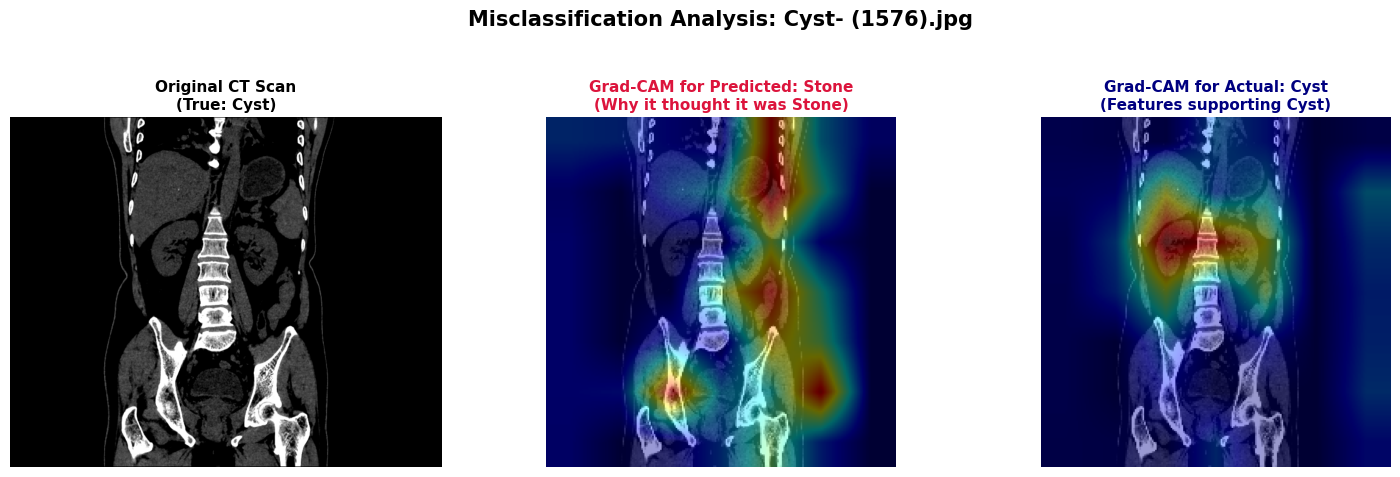

In [ ]:
# ==============================================================
# CELL 7: Grad-CAM Explainability on Misclassified Cases
# ==============================================================
import cv2
import numpy as np

class GradCAMExplainer:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, class_idx):
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()

        target_score = output[0, class_idx]
        target_score.backward()

        gradients = self.gradients.cpu().data.numpy()[0]
        activations = self.activations.cpu().data.numpy()[0]
        weights = np.mean(gradients, axis=(1, 2))

        heatmap = np.zeros(activations.shape[1:], dtype=np.float32)
        for i, w in enumerate(weights):
            heatmap += w * activations[i, :, :]

        heatmap = np.maximum(heatmap, 0)
        max_val = np.max(heatmap)
        if max_val != 0:
            heatmap /= max_val
        return heatmap

explainer = GradCAMExplainer(model, model.stage4)

for i, row in misclassified_df.iterrows():
    raw_img = Image.open(row['full_path']).convert('RGB')
    tensor_input = test_val_transforms(raw_img).unsqueeze(0).to(device)

    actual_idx = class_names.index(row['actual_class'])
    pred_idx = class_names.index(row['predicted_class'])

    # Heatmap for why it predicted Stone
    stone_cam = explainer.generate_heatmap(tensor_input, pred_idx)
    # Heatmap for the actual class (Cyst)
    cyst_cam = explainer.generate_heatmap(tensor_input, actual_idx)

    # Convert original to cv2
    img_cv = cv2.cvtColor(np.array(raw_img), cv2.COLOR_RGB2BGR)
    img_cv = cv2.resize(img_cv, (224, 224))

    # Overlay for Predicted Class
    cam_stone_resized = cv2.resize(stone_cam, (224, 224))
    heatmap_stone = cv2.applyColorMap(np.uint8(255 * cam_stone_resized), cv2.COLORMAP_JET)
    overlay_stone = cv2.addWeighted(img_cv, 0.6, heatmap_stone, 0.4, 0)

    # Overlay for Actual Class
    cam_cyst_resized = cv2.resize(cyst_cam, (224, 224))
    heatmap_cyst = cv2.applyColorMap(np.uint8(255 * cam_cyst_resized), cv2.COLORMAP_JET)
    overlay_cyst = cv2.addWeighted(img_cv, 0.6, heatmap_cyst, 0.4, 0)

    plt.figure(figsize=(15, 4.5))
    plt.suptitle(f"Misclassification Analysis: {row['filename']}", fontsize=15, fontweight='bold', y=1.05)

    plt.subplot(1, 3, 1)
    plt.title(f"Original CT Scan\n(True: {row['actual_class']})", fontsize=11, fontweight='bold')
    plt.imshow(raw_img)
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.title(f"Grad-CAM for Predicted: {row['predicted_class']}\n(Why it thought it was Stone)", fontsize=11, fontweight='bold', color='crimson')
    plt.imshow(cv2.cvtColor(overlay_stone, cv2.COLOR_BGR2RGB))
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.title(f"Grad-CAM for Actual: {row['actual_class']}\n(Features supporting Cyst)", fontsize=11, fontweight='bold', color='navy')
    plt.imshow(cv2.cvtColor(overlay_cyst, cv2.COLOR_BGR2RGB))
    plt.axis('off')

    plt.tight_layout()
    plt.show()


In [ ]:
# ==============================================================
# CELL 8: Backup Misclassifications & Export Report to Drive
# ==============================================================
import shutil

export_dir = '/content/drive/MyDrive/Capstone_Kidney_Project/misclassified_cases'
os.makedirs(export_dir, exist_ok=True)

# Copy misclassified images into Drive folder
for _, row in misclassified_df.iterrows():
    dest_path = os.path.join(export_dir, row['filename'])
    shutil.copy(row['full_path'], dest_path)

# Save the detailed CSV report
report_path = os.path.join(export_dir, 'misclassification_report.csv')
misclassified_df.to_csv(report_path, index=False)

print(f"📁 Misclassified images and report saved to Google Drive at:")
print(f"   {export_dir}")
print(f"   └── misclassification_report.csv")


📁 Misclassified images and report saved to Google Drive at:
   /content/drive/MyDrive/Capstone_Kidney_Project/misclassified_cases
   └── misclassification_report.csv
